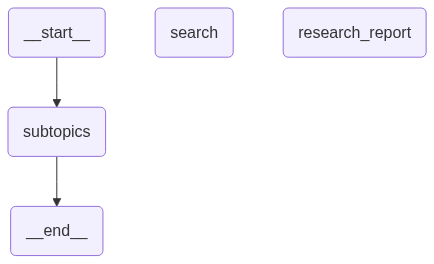

In [1]:
import operator
import os
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import START,END,StateGraph
from pydantic import BaseModel,Field
from typing import TypedDict,Literal,Annotated
from dotenv import load_dotenv
from langgraph.types import Send
from mcp_client import call_tavily_search
import re
load_dotenv()  

model=ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

class ResearchState(TypedDict):
    query: str
    subtopics: list[str]
    search_results: Annotated[list[str], operator.add]
    search_notes: Annotated[list[str], operator.add]
    report: str
    errors: Annotated[list[str], operator.add]

class SearchState(TypedDict):
    query: str
    subtopic: str

def make_subtopics(state: ResearchState) -> dict:
    try:
        response = model.invoke(
            f"""
            You are an AI research assistant.

            Break the following research query into 4-5
            specific subtopics that should be investigated.

            Return only the subtopics as a numbered list.

            Query: {state['query']}
            """
        )

        subtopics_text = response.content

        if isinstance(subtopics_text, list):
            subtopics_text = "\n".join(
                block["text"] if isinstance(block, dict) else str(block)
                for block in subtopics_text
                if isinstance(block, (dict, str))
            )

        subtopics = [
            re.sub(r"^\s*(?:[-*]|\d+[.)])\s*", "", line).strip()
            for line in subtopics_text.splitlines()
            if line.strip()
        ]
        return {
            "subtopics": subtopics,
            "search_notes": ["Created subtopics for the query."],
            "errors": []
        }

    except Exception as e:
        error_message = (
                        "make subtopics failed: " + str(e)
                    )
        return {
    "subtopics": [],
    "errors": [error_message]
}

def dispatch_searches(state:ResearchState):
    return[
        Send("search",
            {
                "query":state["query"],
                "subtopic":subtopic
            }
             )
        for subtopic in state["subtopics"]
    ]
    
def check_subtopics(state:ResearchState) -> Literal["search","end"]:
    if state["subtopics"]:
        return "search"
    else:
        return "end"
    
    
def web_search(query: str) -> str:
    """
    Search the web using Tavily and return relevant results.
    """
    return call_tavily_search(
                query=query,
                max_results=2,
            )


def search_web(state: SearchState) -> dict:
    query = state["query"]
    subtopic = state["subtopic"]
    search_query = f"{query}: {subtopic}"

    try:
            result = web_search(search_query)

            if not result.strip():
                return {
                           "search_results": [],
                "search_notes": [
                    f"No results found for: {subtopic}"
                ],
                "errors": []
                }

            return {
                "search_results": [f"Results for '{subtopic}':\n{result}"],
                "search_notes":[f"completed search for: {subtopic}"],
                "errors": []
            }
    except Exception as e:
              return{
                 "search_results": [],
                 "search_notes": [],
                 "errors": [
                  f"Search failed for '{subtopic}': {str(e)}"
                ]
              }

def generate_research_report(state: ResearchState) -> dict:
    """
    Generate a research report using the collected web search results.
    """
    try:
        report_content = "\n\n".join(state["search_results"])

        if not report_content.strip():
            return {
                "report": "",
                "errors": [
                    "Cannot generate a report because no search results were collected."
                ]
            }

        response = model.invoke(
            f"""
            You are an expert research analyst.

            Research question:
            {state['query']}

            Research subtopics:
            {chr(10).join(state['subtopics'])}

            Web search results:
            {report_content}

            Create a detailed, well-structured research report containing:

            1. Title
            2. Executive summary
            3. Detailed findings for each relevant subtopic
            4. Key insights
            5. Conclusion
            6. References with the source URLs provided in the results

            Instructions:
            - Base factual claims on the supplied search results.
            - Do not invent facts, statistics, or references.
            - Preserve source URLs accurately.
            - Mention when the available evidence is insufficient.
            """
        )

        return {
            "report": response.content,
            "search_notes":[
                "Generated the final research report."
            ]
        }

    except Exception as e:
        return {
            "report":{},
            "errors":[
                f"Report generation failed: {str(e)}"
            ]
        }

      
graph = StateGraph(ResearchState)

graph.add_node("subtopics", make_subtopics)
graph.add_node("search", search_web)
graph.add_node("research_report",generate_research_report)
graph.add_edge(START, "subtopics")
graph.add_conditional_edges(
    "subtopics",
    lambda state: (
        dispatch_searches(state)
        if state["subtopics"]
        else END
    )
)
graph.add_edge("search", "research_report")
graph.add_edge("research_report",END)
# graph.add_edge("research_report", END)

workflow = graph.compile()
workflow